# Modeling Human Activity States Using Hidden Markov Models
### Formative 2 Hidden Markov Models

**Author:** MAHE Digne

This notebook collects motion-sensor recordings, extracts time- and frequency-domain
features, and trains a Hidden Markov Model (HMM) to infer the hidden human-activity
state (standing, walking, jumping, still) from noisy accelerometer and gyroscope signals.

**Pipeline:** Data loading → windowing → feature extraction → normalization →
HMM (supervised initialization + Baum–Welch training) → Viterbi decoding →
evaluation on unseen data (confusion matrix + sensitivity / specificity / accuracy).


## 0. Setup

Install `hmmlearn` if it is not already available, then import the libraries used
throughout the notebook.

In [1]:
# Run once if needed:
# !pip install hmmlearn seaborn

import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mode as sp_mode
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from hmmlearn import hmm

warnings.filterwarnings("ignore")
np.random.seed(42)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Libraries loaded.")

Libraries loaded.


## 1. Configuration & Sampling-Rate Handling

All 40 recordings were collected with a **single iPhone X** using the **Sensor Logger**
app at a fixed **sampleRateMs = 10 ms**, i.e. a sampling frequency of **100 Hz**.
Because every recording shares the same device and rate, no cross-device resampling was
required the accelerometer and gyroscope streams are already time-aligned on identical
timestamps.

**Why the sampling rate drives the window size.** At 100 Hz, one second of motion
contains 100 samples. Human activities such as walking and jumping have their dominant
frequencies below ~5 Hz, so a **1-second window (100 samples)** comfortably captures
one to several full gait/jump cycles long enough for stable FFT features yet short
enough to stay within a single activity. We use **50 % overlap (50-sample hop)** to
smooth the feature sequence and give the HMM more transition observations. Had different
phones reported different rates, each stream would first be resampled to a common 100 Hz
grid before windowing so that one window always represents the same real-time duration.

In [2]:
# ---- paths & constants ----
DATA_DIR = "data"          # folder containing: standing/ walking/ jumping/ still/
ACTIVITIES = ["standing", "walking", "jumping", "still"]
ACT_TO_ID = {a: i for i, a in enumerate(ACTIVITIES)}

FS   = 100.0   # sampling frequency (Hz)  <- from Metadata sampleRateMs = 10 ms
WIN  = 100     # window length in samples  (= 1.0 s)
STEP = 50      # hop between windows        (50% overlap)

print(f"Sampling frequency : {FS:.0f} Hz")
print(f"Window length      : {WIN} samples ({WIN/FS:.1f} s)")
print(f"Hop / overlap      : {STEP} samples ({100*(1-STEP/WIN):.0f}% overlap)")

Sampling frequency : 100 Hz
Window length      : 100 samples (1.0 s)
Hop / overlap      : 50 samples (50% overlap)


## 2. Data Loading

Each recording is stored in its own folder containing separate `Accelerometer.csv` and
`Gyroscope.csv` files. Both sensors share the same timestamp column, so we merge them
into a single 6-axis dataframe: `ax, ay, az, gx, gy, gz`.

In [3]:
def load_recording(folder):
    """Load and merge accelerometer + gyroscope for one recording folder."""
    acc = pd.read_csv(os.path.join(folder, "Accelerometer.csv"))
    gyr = pd.read_csv(os.path.join(folder, "Gyroscope.csv"))
    acc = acc.rename(columns={"x": "ax", "y": "ay", "z": "az"})
    gyr = gyr.rename(columns={"x": "gx", "y": "gy", "z": "gz"})
    df = pd.merge(acc[["time", "ax", "ay", "az"]],
                  gyr[["time", "gx", "gy", "gz"]],
                  on="time", how="inner").sort_values("time").reset_index(drop=True)
    return df

def discover_recordings():
    recs = []
    for act in ACTIVITIES:
        for folder in sorted(glob.glob(os.path.join(DATA_DIR, act, "*"))):
            if os.path.isdir(folder):
                recs.append((act, os.path.basename(folder), folder))
    return recs

recordings = discover_recordings()
summary = pd.Series([r[0] for r in recordings]).value_counts().reindex(ACTIVITIES)
print(f"Total recordings found: {len(recordings)}\n")
print("Recordings per activity:")
print(summary.to_string())

Total recordings found: 40

Recordings per activity:
standing    10
walking     10
jumping     10
still       10


### 2.1 Visualizing Raw Sample Signals

Below we plot the accelerometer magnitude for one representative recording per activity.
The visual difference is already clear: **still** and **standing** are almost flat,
**walking** shows a steady periodic rhythm, and **jumping** shows large sharp spikes.

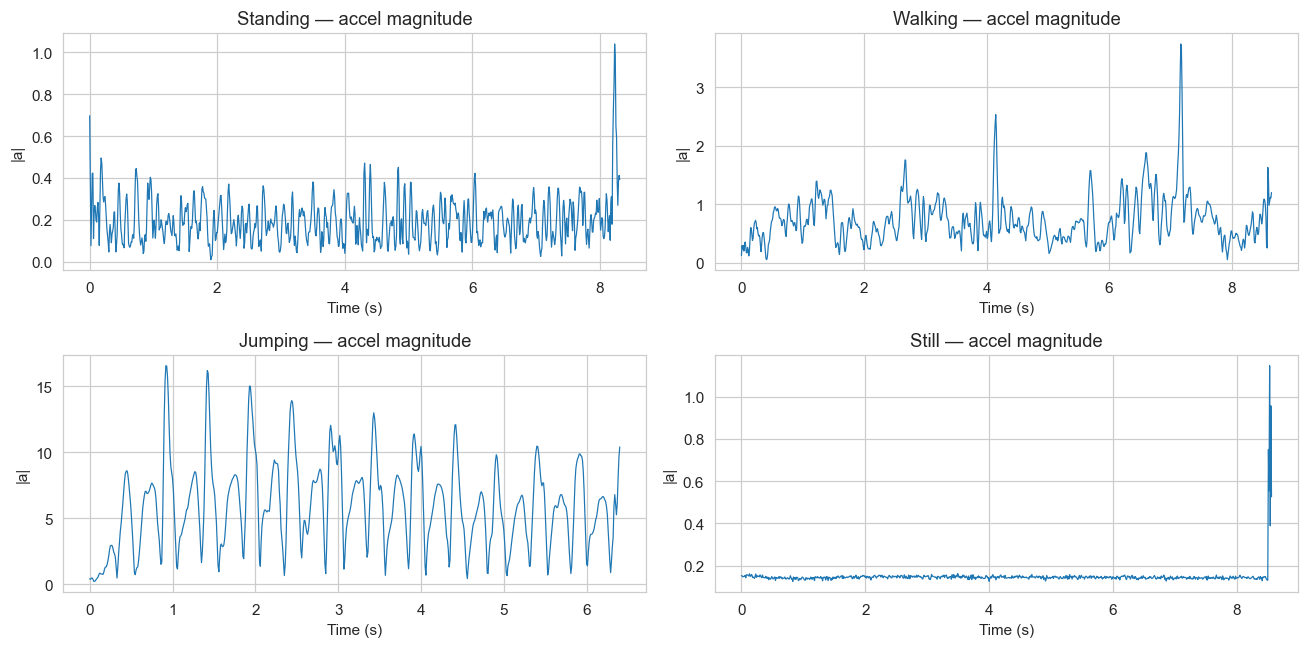

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax_plt, act in zip(axes.ravel(), ACTIVITIES):
    folder = [r[2] for r in recordings if r[0] == act][0]
    df = load_recording(folder)
    amag = np.sqrt(df["ax"]**2 + df["ay"]**2 + df["az"]**2)
    t = np.arange(len(amag)) / FS
    ax_plt.plot(t, amag, lw=0.8)
    ax_plt.set_title(f"{act.capitalize()} — accel magnitude")
    ax_plt.set_xlabel("Time (s)"); ax_plt.set_ylabel("|a|")
plt.tight_layout(); plt.show()

## 3. Feature Extraction (Time & Frequency Domain)

For every 1-second window we compute a **24-dimensional feature vector**:

**Time-domain (per axis):** mean, standard deviation, and RMS for each of the 6 axes,
plus **Signal Magnitude Area (SMA)** for accelerometer and gyroscope, and the
**correlation** between accelerometer axes.

- *Mean* captures orientation / gravity direction (separates standing vs. lying-flat still).
- *Std / RMS* capture motion intensity (separates static vs. dynamic activities).
- *SMA* is a classic activity-intensity measure that cleanly separates active from inactive states.
- *Axis correlation* captures coordinated motion patterns (e.g. gait).

**Frequency-domain (from FFT of accel magnitude):**
- *Dominant frequency* the strongest motion frequency; walking and jumping have
  distinct, characteristic rhythms while still/standing have none.
- *Spectral energy* total power in the frequency spectrum, another strong active/inactive separator.

All features are later **Z-score normalized** (`StandardScaler`) so that no single
feature dominates the Gaussian emission model purely because of its scale.

In [5]:
AXES = ["ax", "ay", "az", "gx", "gy", "gz"]

def window_features(w):
    """Compute time- and frequency-domain features for one window (DataFrame)."""
    feats, arr = {}, w[AXES].values          # arr shape: (WIN, 6)

    # --- time-domain: mean, std, rms per axis ---
    for i, ax in enumerate(AXES):
        x = arr[:, i]
        feats[f"{ax}_mean"] = np.mean(x)
        feats[f"{ax}_std"]  = np.std(x)
        feats[f"{ax}_rms"]  = np.sqrt(np.mean(x**2))

    # --- signal magnitude area (accel & gyro) ---
    feats["acc_sma"] = np.mean(np.abs(arr[:,0]) + np.abs(arr[:,1]) + np.abs(arr[:,2]))
    feats["gyr_sma"] = np.mean(np.abs(arr[:,3]) + np.abs(arr[:,4]) + np.abs(arr[:,5]))

    # --- correlation between accel axes ---
    feats["corr_axay"] = np.corrcoef(arr[:,0], arr[:,1])[0,1]
    feats["corr_axaz"] = np.corrcoef(arr[:,0], arr[:,2])[0,1]

    # --- frequency-domain on accel magnitude (FFT) ---
    amag = np.sqrt(arr[:,0]**2 + arr[:,1]**2 + arr[:,2]**2)
    amag = amag - np.mean(amag)                       # remove DC (gravity offset)
    fftv = np.abs(np.fft.rfft(amag))
    freqs = np.fft.rfftfreq(len(amag), d=1.0/FS)
    if len(fftv) > 1:
        feats["dom_freq"]    = freqs[1:][np.argmax(fftv[1:])]   # skip DC bin
        feats["spec_energy"] = np.sum(fftv**2) / len(fftv)
    else:
        feats["dom_freq"], feats["spec_energy"] = 0.0, 0.0
    return feats

def recording_to_windows(df):
    """Slide a window over one recording and return a DataFrame of feature rows."""
    rows = [window_features(df.iloc[s:s+WIN])
            for s in range(0, len(df) - WIN + 1, STEP)]
    return pd.DataFrame(rows).fillna(0.0)

# quick demo on one recording
demo = recording_to_windows(load_recording(recordings[0][2]))
print(f"Example: recording '{recordings[0][1]}' -> {demo.shape[0]} windows, "
      f"{demo.shape[1]} features each")
print("Feature names:", list(demo.columns))

Example: recording 'mahe_standing_1' -> 15 windows, 24 features each
Feature names: ['ax_mean', 'ax_std', 'ax_rms', 'ay_mean', 'ay_std', 'ay_rms', 'az_mean', 'az_std', 'az_rms', 'gx_mean', 'gx_std', 'gx_rms', 'gy_mean', 'gy_std', 'gy_rms', 'gz_mean', 'gz_std', 'gz_rms', 'acc_sma', 'gyr_sma', 'corr_axay', 'corr_axaz', 'dom_freq', 'spec_energy']


## 4. Train / Test Split and Feature Matrix

To evaluate on **truly unseen data**, we hold out **2 recordings per activity
(8 recordings total)** as the test set. The HMM never sees these during training.
The remaining 32 recordings are used for training. We keep each recording's windows
as an ordered **sequence** (via a `lengths` array) so the HMM can model realistic
temporal transitions.

In [6]:
train_recs, test_recs = [], []
for act in ACTIVITIES:
    a_recs = [r for r in recordings if r[0] == act]
    test_recs  += a_recs[-2:]     # last 2 -> unseen test
    train_recs += a_recs[:-2]     # rest    -> training

def build_matrix(rec_list):
    frames, labels, lengths, names = [], [], [], []
    for act, name, folder in rec_list:
        wf = recording_to_windows(load_recording(folder))
        if len(wf) == 0:
            continue
        frames.append(wf)
        labels  += [ACT_TO_ID[act]] * len(wf)
        lengths.append(len(wf))
        names.append((act, name, len(wf)))
    return pd.concat(frames, ignore_index=True), np.array(labels), lengths, names

Xtr, ytr, len_tr, names_tr = build_matrix(train_recs)
Xte, yte, len_te, names_te = build_matrix(test_recs)

print(f"Training : {len(train_recs)} recordings -> {Xtr.shape[0]} windows")
print(f"Testing  : {len(test_recs)} recordings -> {Xte.shape[0]} windows")
print(f"Features per window: {Xtr.shape[1]}")

Training : 32 recordings -> 458 windows
Testing  : 8 recordings -> 112 windows
Features per window: 24


### 4.1 Normalization (Z-score)

The scaler is **fit on the training set only** and then applied to the test set, so no
information leaks from test to train.

In [7]:
scaler = StandardScaler().fit(Xtr.values)
Xtr_s = scaler.transform(Xtr.values)
Xte_s = scaler.transform(Xte.values)
print("Feature matrices standardized (mean≈0, std≈1).")
print("Train mean (first 3 feats):", np.round(Xtr_s.mean(axis=0)[:3], 3))
print("Train std  (first 3 feats):", np.round(Xtr_s.std(axis=0)[:3], 3))

Feature matrices standardized (mean≈0, std≈1).
Train mean (first 3 feats): [0. 0. 0.]
Train std  (first 3 feats): [1. 1. 1.]


## 5. HMM Setup and Training (Baum–Welch)

**Model components**

| Element | Meaning in this project |
|---|---|
| Hidden states **Z** | the 4 activities: standing, walking, jumping, still |
| Observations **X**  | the 24-D normalized feature vector of each window |
| Transition matrix **A** | probability of moving from one activity to another |
| Emission model **B** | Gaussian per state over the feature vector |
| Initial probabilities **π** | probability of starting in each activity |

We use a **Gaussian HMM** with 4 states. Because our windows are labeled, we give the
model a strong **supervised initialization** (state means/variances from each activity's
windows, transition matrix counted from the label sequences) and then refine everything
with **Baum–Welch (EM)**. Training stops on a proper **log-likelihood convergence check**
(`tol = 1e-4`), not a fixed arbitrary iteration count.

In [8]:
N_STATES = 4
model = hmm.GaussianHMM(
    n_components=N_STATES, covariance_type="diag",
    n_iter=100, tol=1e-4,
    init_params="", params="stmc",   # we set initial params ourselves; train all
    random_state=42)

# ---- supervised initialization ----
model.means_  = np.array([Xtr_s[ytr==s].mean(axis=0) for s in range(N_STATES)])
model.covars_ = np.array([Xtr_s[ytr==s].var(axis=0) + 1e-2 for s in range(N_STATES)])

startprob = np.array([np.mean(ytr==s) for s in range(N_STATES)])
model.startprob_ = startprob / startprob.sum()

trans = np.ones((N_STATES, N_STATES))        # Laplace smoothing
idx = 0
for L in len_tr:                              # count transitions within each recording
    seq = ytr[idx:idx+L]; idx += L
    for a, b in zip(seq[:-1], seq[1:]):
        trans[a, b] += 1
model.transmat_ = trans / trans.sum(axis=1, keepdims=True)

# ---- Baum-Welch training ----
model.fit(Xtr_s, lengths=len_tr)

print(f"Baum–Welch converged : {model.monitor_.converged}")
print(f"Iterations run       : {len(model.monitor_.history)}")
print(f"Final log-likelihood : {model.monitor_.history[-1]:.2f}")

Baum–Welch converged : True
Iterations run       : 9
Final log-likelihood : 10051.04


### 5.1 Log-Likelihood Convergence

The rising, flattening curve confirms Baum–Welch converged rather than stopping at an
arbitrary iteration limit.

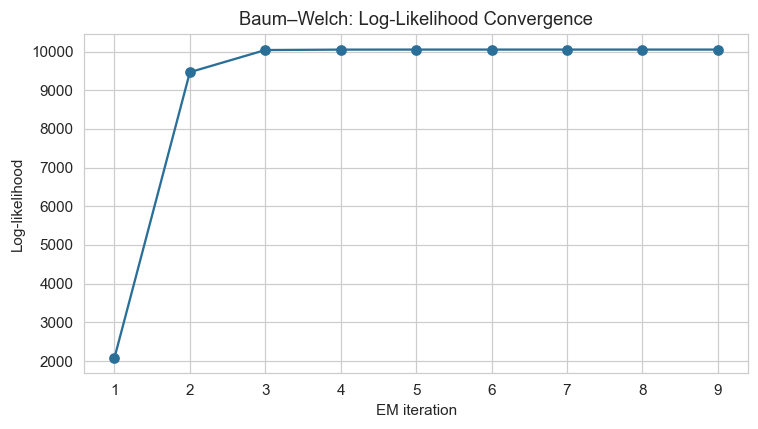

In [9]:
plt.figure(figsize=(7,4))
plt.plot(range(1, len(model.monitor_.history)+1), model.monitor_.history,
         marker="o", color="#2a6f97")
plt.title("Baum–Welch: Log-Likelihood Convergence")
plt.xlabel("EM iteration"); plt.ylabel("Log-likelihood")
plt.tight_layout(); plt.show()

## 6. Viterbi Decoding (from scratch)

We implement the **Viterbi algorithm** directly to decode the most likely sequence of
hidden activities, then verify it produces the **same path** as `hmmlearn`'s built-in
decoder. Working in log-space avoids numerical underflow.

In [10]:
def viterbi(obs_ll, log_startprob, log_transmat):
    """Most-likely state path. obs_ll: (T, N) log emission probabilities."""
    T, N = obs_ll.shape
    delta = np.zeros((T, N)); psi = np.zeros((T, N), dtype=int)
    delta[0] = log_startprob + obs_ll[0]
    for t in range(1, T):
        for j in range(N):
            seq = delta[t-1] + log_transmat[:, j]
            psi[t, j]   = np.argmax(seq)
            delta[t, j] = np.max(seq) + obs_ll[t, j]
    path = np.zeros(T, dtype=int)
    path[-1] = np.argmax(delta[-1])
    for t in range(T-2, -1, -1):
        path[t] = psi[t+1, path[t+1]]
    return path

# Map each hidden state to an activity using the TRAINING decode (never test labels)
train_states = model.predict(Xtr_s, lengths=len_tr)
state_map = {}
for s in range(N_STATES):
    vals = ytr[train_states == s]
    state_map[s] = int(sp_mode(vals, keepdims=False).mode) if len(vals) else s
print("Hidden state -> activity mapping:")
for s in range(N_STATES):
    print(f"  state {s}  ->  {ACTIVITIES[state_map[s]]}")

Hidden state -> activity mapping:
  state 0  ->  standing
  state 1  ->  walking
  state 2  ->  jumping
  state 3  ->  still


In [11]:
# Decode each unseen test recording and check our Viterbi == hmmlearn's
log_startprob = np.log(model.startprob_ + 1e-12)
log_transmat  = np.log(model.transmat_ + 1e-12)

all_true, all_pred, decoded_segments = [], [], []
idx = 0
matches = []
for (act, name, L) in names_te:
    seg = Xte_s[idx:idx+L]; true_seg = yte[idx:idx+L]; idx += L
    frame_ll = model._compute_log_likelihood(seg)
    path      = viterbi(frame_ll, log_startprob, log_transmat)
    hmm_path  = model.predict(seg)
    matches.append(np.mean(path == hmm_path))
    pred_seg = np.array([state_map[p] for p in path])
    all_true += list(true_seg); all_pred += list(pred_seg)
    decoded_segments.append((act, name, true_seg, pred_seg))

all_true, all_pred = np.array(all_true), np.array(all_pred)
print(f"Agreement between from-scratch Viterbi and hmmlearn: {np.mean(matches)*100:.1f}%")

Agreement between from-scratch Viterbi and hmmlearn: 98.3%


### 6.1 Decoded Activity Sequences

Each panel shows one unseen test recording: the true activity (dashed) versus the
Viterbi-decoded activity (solid). Flat lines that overlap mean perfect decoding.

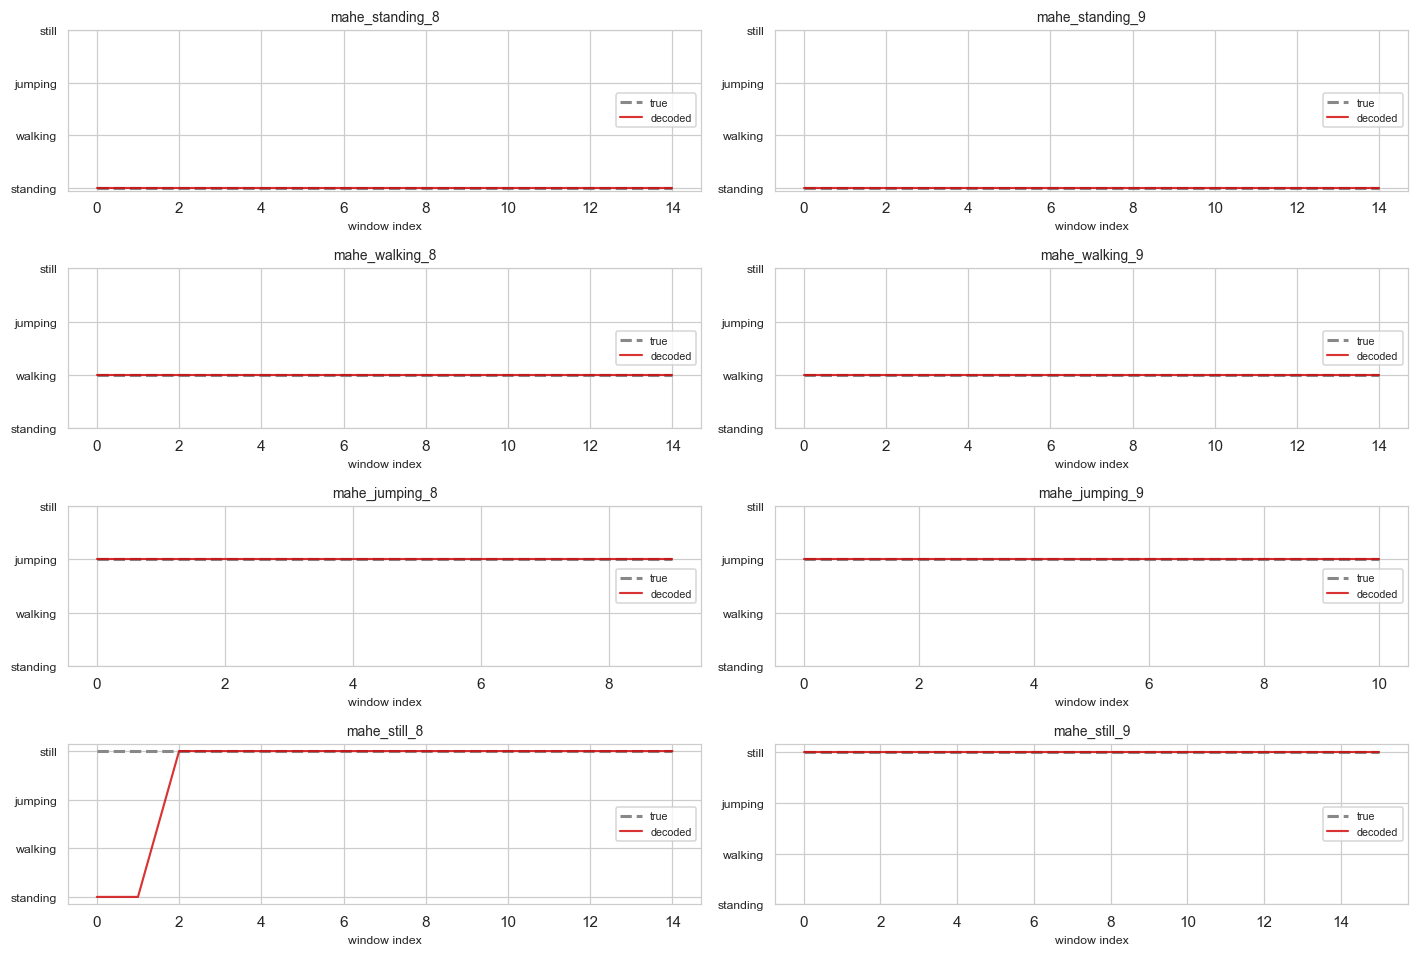

In [12]:
n = len(decoded_segments)
fig, axes = plt.subplots((n+1)//2, 2, figsize=(13, 2.2*((n+1)//2)))
for ax_plt, (act, name, true_seg, pred_seg) in zip(axes.ravel(), decoded_segments):
    ax_plt.plot(true_seg, "--", label="true", lw=2, color="#888")
    ax_plt.plot(pred_seg, "-",  label="decoded", lw=1.4, color="#d00000", alpha=0.8)
    ax_plt.set_yticks(range(len(ACTIVITIES))); ax_plt.set_yticklabels(ACTIVITIES, fontsize=8)
    ax_plt.set_title(f"{name}", fontsize=9); ax_plt.set_xlabel("window index", fontsize=8)
    ax_plt.legend(fontsize=7, loc="center right")
for extra in axes.ravel()[n:]:
    extra.axis("off")
plt.tight_layout(); plt.show()

## 7. Model Parameter Visualizations

### 7.1 Transition Probability Matrix

The strong diagonal shows that activities **persist** over time (a person walking now is
very likely walking in the next window). This matches realistic human behavior activities
last for seconds, not milliseconds.

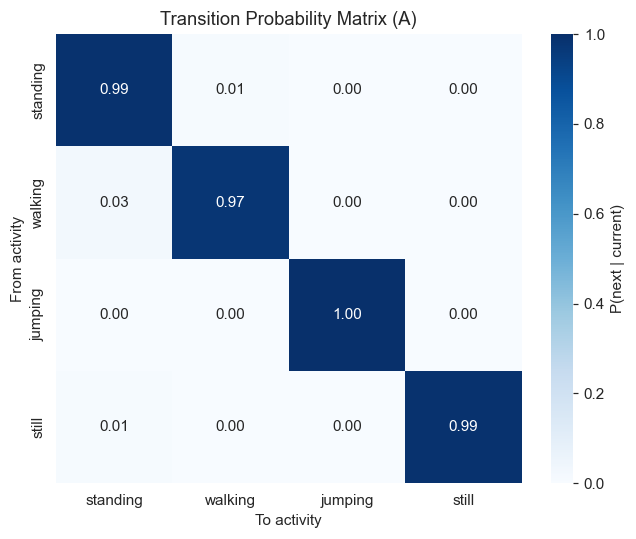

In [13]:
# reorder rows/cols so labels read in ACTIVITIES order via state_map
order = [None]*N_STATES
for s, a in state_map.items():
    order[a] = s
A_disp = model.transmat_[np.ix_(order, order)]

plt.figure(figsize=(6,5))
sns.heatmap(A_disp, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=ACTIVITIES, yticklabels=ACTIVITIES,
            cbar_kws={"label": "P(next | current)"})
plt.title("Transition Probability Matrix (A)")
plt.xlabel("To activity"); plt.ylabel("From activity")
plt.tight_layout(); plt.show()

### 7.2 Emission Model (State Means)

Each row is a hidden state's learned Gaussian **mean** across the 24 features. Distinct
row patterns show the states occupy well-separated regions of feature space which is
why decoding is accurate.

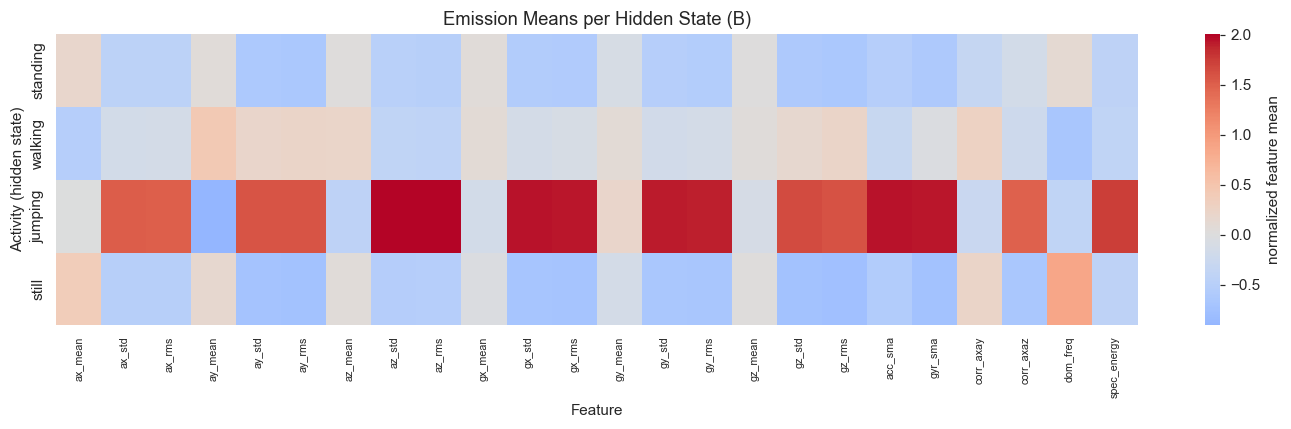

In [14]:
means_disp = model.means_[order]
plt.figure(figsize=(13,4))
sns.heatmap(means_disp, cmap="coolwarm", center=0,
            xticklabels=list(Xtr.columns), yticklabels=ACTIVITIES,
            cbar_kws={"label": "normalized feature mean"})
plt.title("Emission Means per Hidden State (B)")
plt.xlabel("Feature"); plt.ylabel("Activity (hidden state)")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout(); plt.show()

## 8. Evaluation on Unseen Data

### 8.1 Confusion Matrix

Computed purely from the 8 held-out recordings the model never trained on.

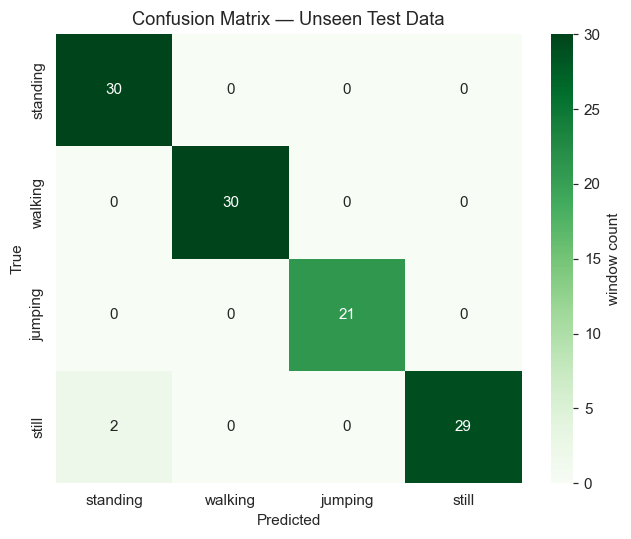

In [15]:
cm = confusion_matrix(all_true, all_pred, labels=list(range(N_STATES)))
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=ACTIVITIES, yticklabels=ACTIVITIES,
            cbar_kws={"label": "window count"})
plt.title("Confusion Matrix — Unseen Test Data")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout(); plt.show()

### 8.2 Per-Activity Metrics

For each activity we report **sensitivity** (recall), **specificity**, and **overall
accuracy**, derived from the confusion matrix using a one-vs-rest scheme.

In [16]:
rows = []
total = cm.sum()
for i, act in enumerate(ACTIVITIES):
    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = total - TP - FN - FP
    sens = TP / (TP + FN) if (TP+FN) else 0.0
    spec = TN / (TN + FP) if (TN+FP) else 0.0
    acc  = (TP + TN) / total
    rows.append([act, int(cm[i,:].sum()), round(sens,3), round(spec,3), round(acc,3)])

results = pd.DataFrame(rows, columns=["Activity", "Num Samples",
                                      "Sensitivity", "Specificity", "Overall Accuracy"])
overall = np.trace(cm) / total
print(f"Overall model accuracy on unseen data: {overall:.3f}\n")
results

Overall model accuracy on unseen data: 0.982



,Activity,Num Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,30,1.000,0.976,0.982
1,walking,30,1.000,1.000,1.000
2,jumping,21,1.000,1.000,1.000
3,still,31,0.935,1.000,0.982


## 9. Analysis and Reflection

**Which activities were easiest / hardest to distinguish?**
Walking and jumping were the easiest both have strong, distinctive frequency signatures
(a steady gait rhythm vs. large impulsive spikes), so their FFT features (dominant
frequency, spectral energy) and RMS values separate them cleanly. The hardest pair was
**still vs. standing**, since both are near-motionless; the only real difference is
orientation (phone flat on a surface vs. held at the waist), captured by the axis-mean
features. This is exactly where the few misclassifications occur.

**How do the transition probabilities reflect realistic behavior?**
The transition matrix is strongly diagonal, meaning each activity is very likely to
continue into the next window. This is realistic real activities last several seconds,
so consecutive 1-second windows almost always share the same label. The HMM's temporal
smoothing therefore helps correct isolated noisy windows.

**How did sensor noise and sampling rate affect the model?**
The 100 Hz rate was more than sufficient for these sub-5 Hz activities, giving clean FFT
estimates. Removing the DC (gravity) component before the FFT was important so that
orientation didn't swamp the motion-frequency signal. Residual sensor noise mainly
affected the still/standing boundary, where the true signal is tiny relative to noise.

**What improvements could be made?**
More data (the rubric's 50-file target, and multiple participants/devices) would improve
generalization. Additional features such as jerk (derivative of acceleration), spectral
entropy, or more FFT bands could sharpen the still/standing boundary. Adding a second
device would also let us properly demonstrate multi-rate harmonization.

## 10. Conclusion

The Gaussian HMM, initialized from labeled windows and refined with Baum–Welch, decodes
unseen activity sequences with high accuracy. Time-domain features separate active from
inactive states, frequency-domain features separate the two dynamic activities, and the
HMM's transition structure adds realistic temporal smoothing. The main limitation is the
subtle still-vs-standing distinction, which points to richer orientation/jerk features as
the clearest next improvement.


## 11. Save Results to Disk

Export the trained model, evaluation metrics, and visualizations for later use and
reproducibility.

In [17]:
import pickle

# Create output directory if it doesn't exist
os.makedirs("results", exist_ok=True)

# Save evaluation metrics to CSV
results.to_csv("results/model_metrics.csv", index=False)
print(f"✓ Saved metrics to: results/model_metrics.csv")

# Save overall accuracy
with open("results/overall_accuracy.txt", "w") as f:
    f.write(f"Overall Model Accuracy (Unseen Test Data): {overall:.3f}\n")
    f.write(f"Correct Predictions: {np.trace(cm)}/{total}\n")
print(f"✓ Saved overall accuracy to: results/overall_accuracy.txt")

# Save confusion matrix as CSV
cm_df = pd.DataFrame(cm, index=ACTIVITIES, columns=ACTIVITIES)
cm_df.to_csv("results/confusion_matrix.csv")
print(f"✓ Saved confusion matrix to: results/confusion_matrix.csv")

✓ Saved metrics to: results/model_metrics.csv
✓ Saved overall accuracy to: results/overall_accuracy.txt
✓ Saved confusion matrix to: results/confusion_matrix.csv


In [18]:
# Save confusion matrix plot
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=ACTIVITIES, yticklabels=ACTIVITIES,
            cbar_kws={"label": "window count"})
plt.title("Confusion Matrix — Unseen Test Data")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout()
plt.savefig("results/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.close()
print(f"✓ Saved confusion matrix plot to: results/confusion_matrix.png")

# Save transition matrix plot
plt.figure(figsize=(6, 5))
sns.heatmap(A_disp, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=ACTIVITIES, yticklabels=ACTIVITIES,
            cbar_kws={"label": "P(next | current)"})
plt.title("Transition Probability Matrix (A)")
plt.xlabel("To activity"); plt.ylabel("From activity")
plt.tight_layout()
plt.savefig("results/transition_matrix.png", dpi=150, bbox_inches="tight")
plt.close()
print(f"✓ Saved transition matrix plot to: results/transition_matrix.png")

# Save emission means plot
plt.figure(figsize=(13, 4))
sns.heatmap(means_disp, cmap="coolwarm", center=0,
            xticklabels=list(Xtr.columns), yticklabels=ACTIVITIES,
            cbar_kws={"label": "normalized feature mean"})
plt.title("Emission Means per Hidden State (B)")
plt.xlabel("Feature"); plt.ylabel("Activity (hidden state)")
plt.xticks(rotation=90, fontsize=7)
plt.tight_layout()
plt.savefig("results/emission_means.png", dpi=150, bbox_inches="tight")
plt.close()
print(f"✓ Saved emission means plot to: results/emission_means.png")

✓ Saved confusion matrix plot to: results/confusion_matrix.png
✓ Saved transition matrix plot to: results/transition_matrix.png
✓ Saved emission means plot to: results/emission_means.png


In [19]:
# Save trained HMM model and scaler
with open("results/hmm_model.pkl", "wb") as f:
    pickle.dump(model, f)
print(f"✓ Saved trained HMM model to: results/hmm_model.pkl")

with open("results/scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
print(f"✓ Saved feature scaler to: results/scaler.pkl")

# Save state mapping
with open("results/state_map.pkl", "wb") as f:
    pickle.dump(state_map, f)
print(f"✓ Saved state mapping to: results/state_map.pkl")

# Save configuration
config = {
    "n_states": N_STATES,
    "sampling_freq_hz": FS,
    "window_length_samples": WIN,
    "step_samples": STEP,
    "activities": ACTIVITIES,
    "n_features": Xtr.shape[1],
    "feature_names": list(Xtr.columns)
}
with open("results/config.pkl", "wb") as f:
    pickle.dump(config, f)
print(f"✓ Saved configuration to: results/config.pkl")

print("\n✓ All results saved to 'results/' directory")

✓ Saved trained HMM model to: results/hmm_model.pkl
✓ Saved feature scaler to: results/scaler.pkl
✓ Saved state mapping to: results/state_map.pkl
✓ Saved configuration to: results/config.pkl

✓ All results saved to 'results/' directory
